# 08 — Evaluación de hipótesis

## Objetivo

Evaluar formalmente las tres hipótesis del proyecto. Para cada una se informan
el test, el **tamaño del efecto**, un **intervalo de confianza** (bootstrap,
2.000 réplicas, semilla fija) y una prueba de **robustez**, además del p-valor.

Todos los tests se recalculan acá desde `data/processed/`; H3 se evalúa con el
modelo económico de la notebook 07.

Se usan tests no paramétricos, porque el USD/m² y el precio relativo son
asimétricos y tienen colas pesadas (notebook 04). Se evalúan varias pruebas, por
lo que se usa un nivel de 1 % como referencia más exigente que el 5 %.

In [1]:
# Entorno: ubicar la raíz del repositorio (la carpeta que contiene src/)
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import BASE_FEATURES, PROCESSED_DIR, MIN_COMPARABLES, MARGEN_MINIMO_PCT

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
N_BOOT = 2000

df = pd.read_csv(BASE_FEATURES)
df["Precio_Relativo_pct"] = -df["Gap_Subvaluacion_pct"]
print("Avisos:", len(df))


def ic_bootstrap(x, y, estad=lambda a, b: np.median(a) - np.median(b), n=N_BOOT):
    """IC 95 % percentil del estadístico, remuestreando cada grupo por separado."""
    x, y = np.asarray(x), np.asarray(y)
    reps = [estad(rng.choice(x, len(x)), rng.choice(y, len(y))) for _ in range(n)]
    return np.percentile(reps, [2.5, 97.5])


def comparar(x, y, nombre, alternativa="less", relativa=False):
    """Mann-Whitney + diferencia de medianas + probabilidad de superioridad + IC."""
    x, y = pd.Series(x).dropna(), pd.Series(y).dropna()
    u, p = stats.mannwhitneyu(x, y, alternative=alternativa)
    if relativa:
        est = lambda a, b: (np.median(a) - np.median(b)) / np.median(b) * 100
    else:
        est = lambda a, b: np.median(a) - np.median(b)
    lo, hi = ic_bootstrap(x, y, est)
    return {"Comparación": nombre, "n1": len(x), "n2": len(y),
            "Diferencia de medianas": round(est(x.values, y.values), 1),
            "IC 95 %": f"[{lo:.1f}; {hi:.1f}]",
            "P(grupo 1 < grupo 2)": round(1 - u / (len(x) * len(y)), 3),
            "p-valor": f"{p:.1e}"}

Avisos: 9499


## H1 — Descuento por condición

> Los departamentos que necesitan obra presentan un USD/m² menor que los
> reciclados o en buen estado, aun dentro de un mismo estrato.

- **Comparación directa:** USD/m² de `Necesita_obra` contra `Reciclada_refaccionada`
  (diferencia de medianas en %).
- **Comparación controlada:** precio relativo al benchmark del estrato (barrio,
  ambientes, superficie y antigüedad), `Necesita_obra` contra `Buen_o_reciclada`
  (diferencia en puntos porcentuales). Es la prueba relevante para H1, porque
  compara cada aviso con sus comparables.
- **Robustez:** se repite la comparación controlada sin los avisos con señal de
  estado contradictoria y solo con los estratos de nivel 1 o 2 (los más finos).

La probabilidad de superioridad es la probabilidad de que una unidad que
necesita obra, elegida al azar, esté más barata que una del otro grupo
(0,5 = sin diferencia).

In [2]:
obra = df["Estado_Propiedad"].eq("Necesita_obra")
recic = df["Estado_Propiedad"].eq("Reciclada_refaccionada")
bueno = df["Estado_Agrupado"].eq("Buen_o_reciclada")
no_contra = ~df["Flag_Senal_Contradictoria"].fillna(False).astype(bool)
fino = df["Nivel_Benchmark"].isin([1, 2])
rel = df["Precio_Relativo_pct"]

h1 = pd.DataFrame([
    comparar(df.loc[obra, "USD_m2_Homogeneizado"], df.loc[recic, "USD_m2_Homogeneizado"],
             "Directa: USD/m² (%), obra vs. reciclada", relativa=True),
    comparar(rel[obra], rel[bueno], "Controlada: precio relativo (pp), obra vs. buen/reciclada"),
    comparar(rel[obra & no_contra], rel[bueno & no_contra], "Robustez: sin señales contradictorias"),
    comparar(rel[obra & fino], rel[bueno & fino], "Robustez: solo estratos de nivel 1 y 2"),
])
display(h1)

,Comparación,n1,n2,Diferencia de medianas,IC 95 %,P(grupo 1 < grupo 2),p-valor
0,"Directa: USD/m² (%), obra vs. reciclada",439,977,-25.4,[-30.2; -22.2],0.757,2.4e-54
1,"Controlada: precio relativo (pp), obra vs. buen/reciclada",435,3010,-17.5,[-19.9; -15.3],0.747,1.1e-62
2,Robustez: sin señales contradictorias,368,3000,-16.4,[-18.4; -14.5],0.737,3.1e-50
3,Robustez: solo estratos de nivel 1 y 2,369,2501,-17.3,[-19.4; -15.2],0.754,3.6e-56


Kruskal-Wallis entre 12 comunas (≥ 10 avisos a reciclar): H = 13.50, p = 0.262, épsilon² = 0.006


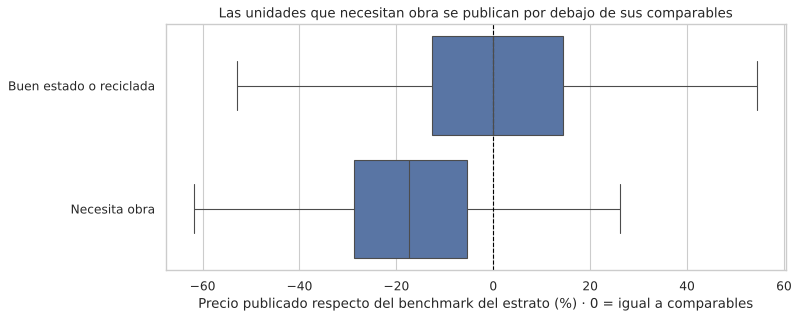

In [3]:
# Heterogeneidad: ¿el descuento es similar entre comunas?
grupos = [g["Precio_Relativo_pct"].dropna().values
          for _, g in df[obra].groupby("Comuna") if g["Precio_Relativo_pct"].notna().sum() >= 10]
h, p_kw = stats.kruskal(*grupos)
n_kw = sum(len(g) for g in grupos)
epsilon2 = (h - len(grupos) + 1) / (n_kw - len(grupos))
print(f"Kruskal-Wallis entre {len(grupos)} comunas (≥ 10 avisos a reciclar): "
      f"H = {h:.2f}, p = {p_kw:.3f}, épsilon² = {max(epsilon2, 0):.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
datos = df[(obra | bueno) & rel.between(-80, 120)].assign(
    Grupo=lambda d: np.where(d["Estado_Propiedad"].eq("Necesita_obra"), "Necesita obra", "Buen estado o reciclada"))
sns.boxplot(data=datos, x="Precio_Relativo_pct", y="Grupo", showfliers=False, ax=ax)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set(title="Las unidades que necesitan obra se publican por debajo de sus comparables",
       xlabel="Precio publicado respecto del benchmark del estrato (%) · 0 = igual a comparables", ylabel="")
plt.show()

**Cómo leer las cifras.** En la mediana, las unidades que necesitan obra se
publican un **17,4 % por debajo de su benchmark** (es su precio relativo), y las
que están en buen estado o recicladas, prácticamente en el benchmark (−0,04 %).
La **diferencia entre ambos grupos es de 17,5 puntos porcentuales**: es la que se
prueba y la que lleva intervalo. Las dos cifras miden cosas distintas (un nivel y
una diferencia) y no se contradicen.

**Resultado H1: se sostiene.** El descuento es estadísticamente significativo,
su intervalo de confianza no incluye el cero y se mantiene al excluir las
señales contradictorias y al usar solo los estratos más finos. No difiere de
forma relevante entre comunas (el épsilon² es muy bajo). El modelo hedónico de
la notebook 10, que controla por amenities y otras características, estima un
descuento algo menor (≈ 14 % frente a buen estado), coherente con este
resultado.

**Relevancia práctica.** El descuento es real, pero su magnitud es moderada. La
notebook 07 muestra que no alcanza para pagar una obra media o integral (ver H3).

## H2 — Dispersión condicional (reformulada)

> **Planteo original:** una mayor dispersión del USD/m² dentro de un estrato
> homogéneo indica oportunidades.

**Problema del planteo original.** Una propiedad es "barata" si está 25 % o más
por debajo de la mediana de sus comparables. En un estrato más disperso, por
construcción, más avisos caen lejos de la mediana: la correlación positiva entre
dispersión y proporción de baratas es en buena parte **mecánica** y no prueba
nada sobre oportunidades. Para que la hipótesis diga algo, hay que preguntar si
la cola inferior es **más pesada de lo que la propia dispersión implica**.

> **H2 reformulada:** en los estratos homogéneos, la proporción de avisos 25 % o
> más por debajo de la mediana del estrato supera la que se esperaría solo por
> su dispersión, y ese exceso crece con la dispersión.

**Nulo que preserva la dispersión.** Se estandariza el log del USD/m² de cada
aviso con la mediana y el rango intercuartílico de su estrato. Bajo el nulo,
todos los estratos comparten la misma forma de distribución y solo difieren en
nivel y escala. Para cada estrato, la proporción esperada en la cola es la de la
distribución estandarizada conjunta por debajo del corte que corresponde a su
dispersión. Además, se simula la correlación dispersión–cola bajo el nulo
(500 réplicas, remuestreando con el tamaño de cada estrato) para compararla con
la observada.

Estratos: barrio × ambientes × banda de superficie, con al menos 10 avisos.
Se mantiene, como descripción, la relación con las categorías del proyecto
(`Barata` y `Barata_requiere_verificacion`).


Estratos analizados: 289


,rho,IC 95 %,p-valor
Todas las baratas,0.477,[0.37; 0.57],8.5e-18
Solo baratas sin indicadores de error,0.433,[0.33; 0.53],1.3e-14
Baratas que requieren verificación,0.277,[0.18; 0.37],1.7e-06


Spearman parcial (baratas sin error vs. dispersión, controlando tamaño del estrato): 0.451


,Estratos,Avisos,% baratas sin error,% requieren verificación
Quintil,,,,
Q1 menos disperso,58.0,1052.0,3.3,0.2
Q2,58.0,1847.0,4.2,0.6
Q3,57.0,1571.0,7.3,0.9
Q4,58.0,1864.0,8.7,1.2
Q5 más disperso,58.0,1884.0,10.1,1.5


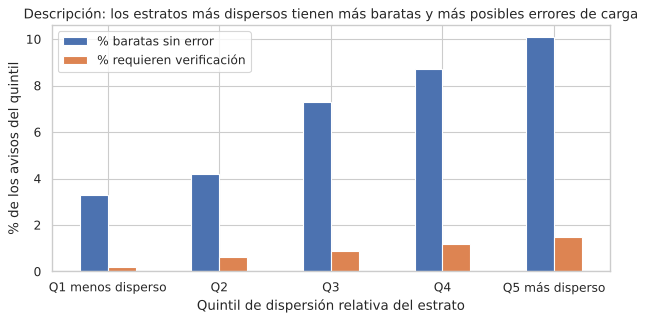

In [4]:
estrato = ["Barrio_Oficial", "Ambientes_Grupo", "Banda_Superficie"]
clas = df["Clasificacion_Oportunidad"].fillna("")
e = (df.assign(Barata_total=clas.str.startswith("Barata"),
               Barata_limpia=clas.eq("Barata"),
               Verificacion=clas.eq("Barata_requiere_verificacion"))
     .groupby(estrato, observed=True)
     .agg(N=("USD_m2_Homogeneizado", "size"),
          Mediana=("USD_m2_Homogeneizado", "median"),
          IQR=("USD_m2_Homogeneizado", lambda x: x.quantile(.75) - x.quantile(.25)),
          Pct_baratas=("Barata_total", "mean"),
          Pct_baratas_limpias=("Barata_limpia", "mean"),
          Pct_verificacion=("Verificacion", "mean")))
e = e[e["N"] >= MIN_COMPARABLES].copy()
e["Dispersion_relativa"] = e["IQR"] / e["Mediana"]


def spearman_ic(x, y, n=N_BOOT):
    x, y = np.asarray(x), np.asarray(y)
    rho, p = stats.spearmanr(x, y)
    idx = [rng.integers(0, len(x), len(x)) for _ in range(n)]
    reps = [stats.spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(reps, [2.5, 97.5])
    return {"rho": round(rho, 3), "IC 95 %": f"[{lo:.2f}; {hi:.2f}]", "p-valor": f"{p:.1e}"}


h2 = pd.DataFrame({
    "Todas las baratas": spearman_ic(e["Dispersion_relativa"], e["Pct_baratas"]),
    "Solo baratas sin indicadores de error": spearman_ic(e["Dispersion_relativa"], e["Pct_baratas_limpias"]),
    "Baratas que requieren verificación": spearman_ic(e["Dispersion_relativa"], e["Pct_verificacion"]),
}).T
print("Estratos analizados:", len(e))
display(h2)

# Control por tamaño del estrato: correlación parcial (rangos) controlando N
r = e[["Dispersion_relativa", "Pct_baratas_limpias", "N"]].rank()
res = lambda col: r[col] - np.polyval(np.polyfit(r["N"], r[col], 1), r["N"])
rho_parcial = np.corrcoef(res("Dispersion_relativa"), res("Pct_baratas_limpias"))[0, 1]
print(f"Spearman parcial (baratas sin error vs. dispersión, controlando tamaño del estrato): {rho_parcial:.3f}")

e["Quintil"] = pd.qcut(e["Dispersion_relativa"], 5, labels=["Q1 menos disperso", "Q2", "Q3", "Q4", "Q5 más disperso"])
quint = (e.groupby("Quintil", observed=True)
         .apply(lambda g: pd.Series({"Estratos": len(g), "Avisos": g["N"].sum(),
                                     "% baratas sin error": (g["Pct_baratas_limpias"] * g["N"]).sum() / g["N"].sum() * 100,
                                     "% requieren verificación": (g["Pct_verificacion"] * g["N"]).sum() / g["N"].sum() * 100}))
         .round(1))
display(quint)

fig, ax = plt.subplots(figsize=(9, 4))
quint[["% baratas sin error", "% requieren verificación"]].plot.bar(ax=ax, rot=0)
ax.set(title="Descripción: los estratos más dispersos tienen más baratas y más posibles errores de carga",
       xlabel="Quintil de dispersión relativa del estrato", ylabel="% de los avisos del quintil")
plt.show()

,rho,IC 95 %,p-valor
Cola observada vs. dispersión,0.549,[0.46; 0.63],4.1e-24
Cola esperada por la dispersión (nulo),0.992,[0.99; 0.99],1.4e-259
Exceso de cola (observada − esperada) vs. dispersión,-0.269,[-0.37; -0.15],3.4e-06


Spearman dispersión–cola bajo el nulo (simulado): mediana 0.72, 95 % de las réplicas en [0.66; 0.78]
Proporción de avisos en la cola: observada 9.6 %, esperada por la dispersión 9.6 %


,Estratos,Cola observada (%),Esperada por la dispersión (%),Exceso (pp)
Q1 menos disperso,58.0,4.1,1.5,2.6
Q2,58.0,4.8,4.7,0.1
Q3,57.0,9.9,8.0,1.9
Q4,58.0,10.8,11.2,-0.4
Q5 más disperso,58.0,15.8,18.5,-2.7


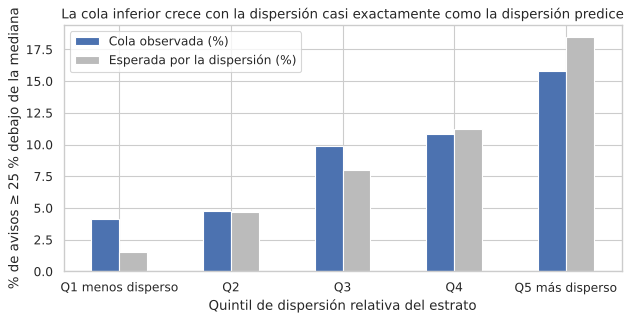

In [5]:
# Nulo que preserva la dispersión
d2 = df[df["USD_m2_Homogeneizado"].gt(0)].copy()
d2["lx"] = np.log(d2["USD_m2_Homogeneizado"])
d2 = d2[d2.groupby(estrato, observed=True)["lx"].transform("size") >= MIN_COMPARABLES]
g2 = d2.groupby(estrato, observed=True)["lx"]
d2["med"] = g2.transform("median")
d2["iqr"] = g2.transform(lambda x: x.quantile(.75) - x.quantile(.25))
d2["z"] = (d2["lx"] - d2["med"]) / d2["iqr"]
d2["Cola"] = d2["lx"] <= d2["med"] + np.log(0.75)          # ≥ 25 % debajo de la mediana

cola = (d2.groupby(estrato, observed=True)
        .agg(N=("lx", "size"), iqr=("iqr", "first"), Observada=("Cola", "mean"),
             Dispersion_relativa=("USD_m2_Homogeneizado",
                                  lambda x: (x.quantile(.75) - x.quantile(.25)) / x.median())))
z_pool = np.sort(d2["z"].to_numpy())
cola["Esperada"] = np.searchsorted(z_pool, np.log(0.75) / cola["iqr"], side="right") / len(z_pool)
cola["Exceso"] = cola["Observada"] - cola["Esperada"]

reps = []
for _ in range(500):
    sim = [np.mean(rng.choice(z_pool, n_) <= np.log(0.75) / i) for n_, i in zip(cola["N"], cola["iqr"])]
    reps.append(stats.spearmanr(cola["Dispersion_relativa"], sim)[0])
rho_nulo = np.percentile(reps, [2.5, 50, 97.5])

h2_nulo = pd.DataFrame({
    "Cola observada vs. dispersión": spearman_ic(cola["Dispersion_relativa"], cola["Observada"]),
    "Cola esperada por la dispersión (nulo)": spearman_ic(cola["Dispersion_relativa"], cola["Esperada"]),
    "Exceso de cola (observada − esperada) vs. dispersión": spearman_ic(cola["Dispersion_relativa"], cola["Exceso"]),
}).T
display(h2_nulo)
print(f"Spearman dispersión–cola bajo el nulo (simulado): mediana {rho_nulo[1]:.2f}, "
      f"95 % de las réplicas en [{rho_nulo[0]:.2f}; {rho_nulo[2]:.2f}]")
pond = lambda g, c: (g[c] * g["N"]).sum() / g["N"].sum() * 100
print(f"Proporción de avisos en la cola: observada {pond(cola, 'Observada'):.1f} %, "
      f"esperada por la dispersión {pond(cola, 'Esperada'):.1f} %")

cola["Quintil"] = pd.qcut(cola["Dispersion_relativa"], 5,
                          labels=["Q1 menos disperso", "Q2", "Q3", "Q4", "Q5 más disperso"])
qc = pd.DataFrame({q: {"Estratos": len(g), "Cola observada (%)": pond(g, "Observada"),
                       "Esperada por la dispersión (%)": pond(g, "Esperada")}
                   for q, g in cola.groupby("Quintil", observed=True)}).T.round(1)
qc["Exceso (pp)"] = qc["Cola observada (%)"] - qc["Esperada por la dispersión (%)"]
display(qc)

fig, ax = plt.subplots(figsize=(9, 4))
qc[["Cola observada (%)", "Esperada por la dispersión (%)"]].plot.bar(ax=ax, rot=0, color=["#4C72B0", "#BBBBBB"])
ax.set(title="La cola inferior crece con la dispersión casi exactamente como la dispersión predice",
       xlabel="Quintil de dispersión relativa del estrato",
       ylabel="% de avisos ≥ 25 % debajo de la mediana")
plt.show()


**Resultado H2: no se sostiene en su forma original y la versión reformulada
tampoco.** La relación entre dispersión y proporción de baratas existe, pero es
la que produce la propia definición de "barata": la proporción de avisos en la
cola es la que la dispersión predice (cifras arriba) y la correlación observada
no supera la que se obtiene bajo el nulo. El exceso de cola no crece con la
dispersión; si algo, es mayor en los estratos **menos** dispersos, donde unos
pocos avisos muy alejados de un grupo homogéneo pesan más (y son más candidatos a
errores de carga o a productos distintos, como mostró la revisión de la lista de
visitas en la notebook 09).

**Qué queda como descripción.** Los estratos más dispersos concentran, en
términos absolutos, más baratas y más casos que requieren verificación. La
dispersión sirve para describir dónde está la cola y como señal de que el
benchmark del estrato es menos confiable, no como evidencia de oportunidad.


## H3 — Existencia de oportunidades de flipping

> En una parte de los casos que necesitan obra, el descuento de entrada supera
> el costo de refacción, los costos de transacción, la tenencia y las
> contingencias, con margen positivo aun en el escenario conservador.

Se evalúa con el modelo económico corregido de la notebook 07, que usa los
supuestos con fuente de `data/supuestos_flipping.csv`. Se informa la cantidad de
unidades rentables en cada escenario.

**Por qué no se informa un intervalo de confianza.** Las 428 unidades son todas
las que necesitan obra en la base, no una muestra, y el ROI de cada una es un
cálculo determinístico a partir de los supuestos de costo. Un intervalo de
Wilson describiría la variabilidad de una muestra que no existe. La
incertidumbre relevante está en los supuestos (nivel de obra, costos,
negociación), y se mide con la sensibilidad de la notebook 07.

In [6]:
flip = pd.read_csv(PROCESSED_DIR / "flipping_modelo_economico.csv")

filas = []
for esc in ["Conservador", "Base", "Optimista"]:
    for umbral, etiqueta in [(0, "ROI > 0"), (MARGEN_MINIMO_PCT, f"ROI ≥ {MARGEN_MINIMO_PCT} %")]:
        k = int((flip[f"ROI_{esc}_pct"] > umbral).sum()) if umbral == 0 else int((flip[f"ROI_{esc}_pct"] >= umbral).sum())
        filas.append({"Escenario": esc, "Criterio": etiqueta, "Unidades": k, "n": len(flip),
                      "%": round(k / len(flip) * 100, 1)})
h3 = pd.DataFrame(filas)
display(h3)
display(flip["Decision"].value_counts().to_frame("Unidades"))
print("ROI base mediano:", round(flip["ROI_Base_pct"].median(), 1), "%")
print("Obra máxima pagable (mediana):", round(flip["Obra_Max_Pagable_USD_m2"].median()), "USD/m²")

,Escenario,Criterio,Unidades,n,%
0,Conservador,ROI > 0,0,428,0.0
1,Conservador,ROI ≥ 15 %,0,428,0.0
2,Base,ROI > 0,2,428,0.5
3,Base,ROI ≥ 15 %,0,428,0.0
4,Optimista,ROI > 0,62,428,14.5
5,Optimista,ROI ≥ 15 %,16,428,3.7


,Unidades
Decision,
Descartar,428


ROI base mediano: -38.8 %
Obra máxima pagable (mediana): 24 USD/m²


**Resultado H3: no se sostiene.** Con los supuestos con fuente, ninguna unidad
es rentable en el escenario conservador. En el escenario base, la proporción rentable es
marginal. La sensibilidad de la notebook 07 muestra que el resultado solo cambia
si la obra fuera liviana en todos los casos, lo que no es consistente con la
evidencia del texto de los avisos.

H3 se reformula como un hallazgo: **el descuento de las unidades a reciclar
alcanza para cubrir los costos de transacción y de tenencia, pero no el de una
obra media o integral.** La herramienta útil para el fondo es el precio máximo
de oferta de cada unidad.

## Síntesis

In [7]:
sintesis = pd.DataFrame({
    "Hipótesis": ["H1 — Descuento por condición", "H2 — Dispersión condicional", "H3 — Flipping rentable"],
    "Evidencia principal": [
        f"Precio relativo {h1.loc[1, 'Diferencia de medianas']} pp vs. buen estado/reciclada, IC {h1.loc[1, 'IC 95 %']}",
        f"Cola observada {pond(cola, 'Observada'):.1f} % vs. {pond(cola, 'Esperada'):.1f} % esperada por la dispersión; exceso vs. dispersión rho {h2_nulo.iloc[2]['rho']}",
        f"{h3.loc[0, 'Unidades']} de {h3.loc[0, 'n']} rentables en el conservador; {h3.loc[2, 'Unidades']} en el base",
    ],
    "Robustez": ["Se mantiene sin señales contradictorias y en estratos finos",
                 "La correlación observada no supera la del nulo que preserva la dispersión",
                 "Solo cambia con obra liviana generalizada"],
    "Estado": ["Se sostiene", "No se sostiene (la relación es mecánica)", "No se sostiene (reformulada)"],
})
display(sintesis)

,Hipótesis,Evidencia principal,Robustez,Estado
0,H1 — Descuento por condición,"Precio relativo -17.5 pp vs. buen estado/reciclada, IC [-19.9; -15.3]",Se mantiene sin señales contradictorias y en estratos finos,Se sostiene
1,H2 — Dispersión condicional,Cola observada 9.6 % vs. 9.6 % esperada por la dispersión; exceso vs. dispersión rho -0.269,La correlación observada no supera la del nulo que preserva la dispersión,No se sostiene (la relación es mecánica)
2,H3 — Flipping rentable,0 de 428 rentables en el conservador; 2 en el base,Solo cambia con obra liviana generalizada,No se sostiene (reformulada)


Análisis complementario: heterogeneidad territorial y micromercados

Pregunta: ¿Cómo varían el nivel de precios, la dispersión y la proporción de avisos con descuento entre barrios de CABA?

Este análisis complementa H2, profundizando en las diferencias territoriales. Es descriptivo y exploratorio, por lo que no constituye una cuarta hipótesis confirmatoria. Se excluyen barrios con menos de 30 avisos válidos para evitar comparaciones muy inestables.


Barrios incluidos: 43 | Avisos incluidos: 9,433 de 9,499 válidos


,N,Mediana_USD_m2,IQR_USD_m2,IQR_relativo_pct,Candidatas,Pct_candidatas
Barrio_Oficial,,,,,,
Nueva Pompeya,43,1296.9,522.0,40.3,14,32.6
Parque Avellaneda,32,1454.6,720.0,49.5,8,25.0
Paternal,36,1830.1,851.2,46.5,9,25.0
Velez Sarsfield,60,1625.9,486.6,29.9,12,20.0
La Boca,60,1442.6,473.6,32.8,11,18.3
Constitucion,189,1390.9,685.3,49.3,33,17.5
Villa Gral. Mitre,87,1809.5,584.1,32.3,14,16.1
Villa Pueyrredon,60,2224.8,726.8,32.7,9,15.0
Parque Chacabuco,144,2035.9,804.4,39.5,21,14.6


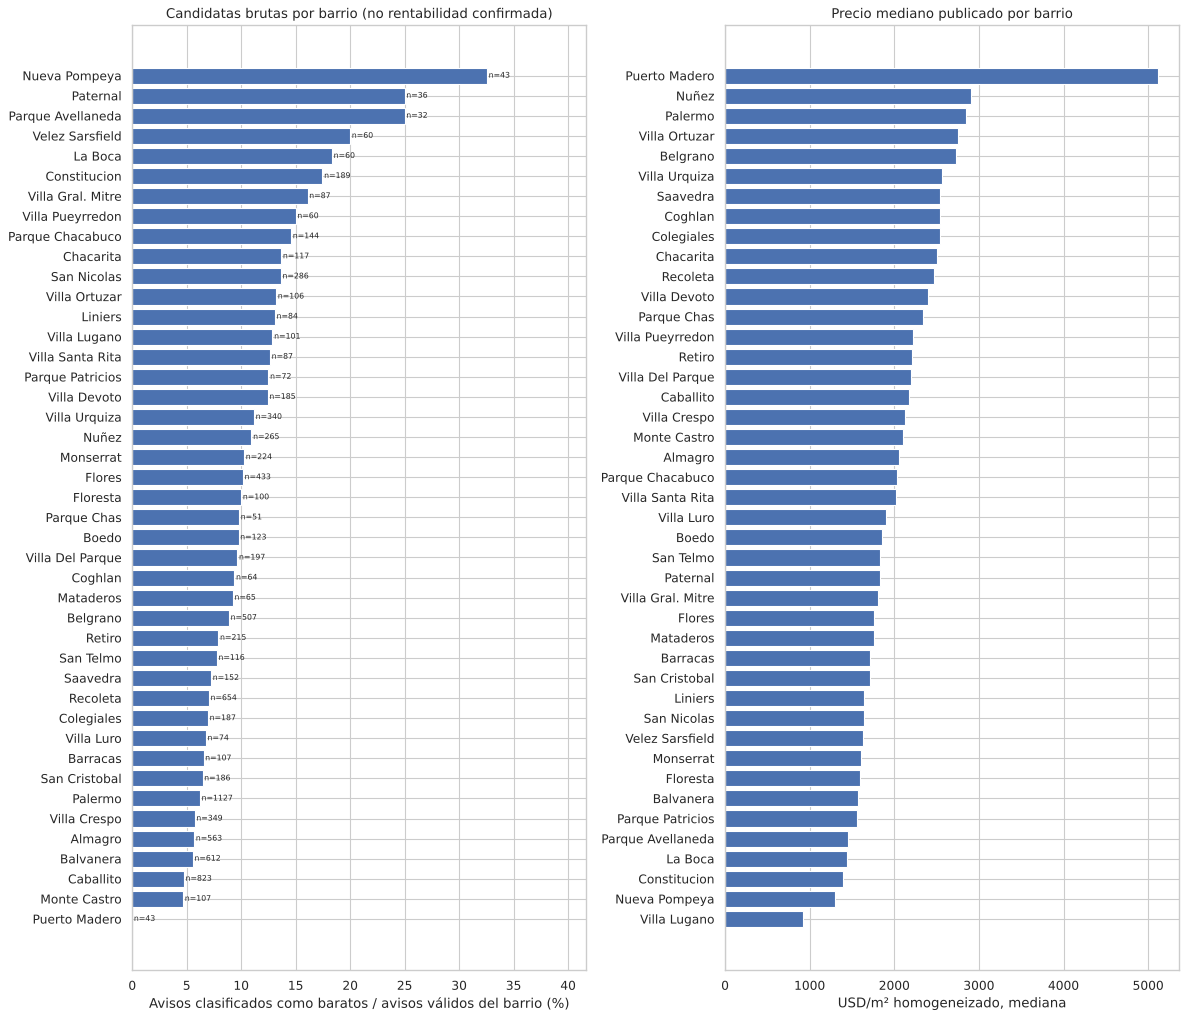

Spearman entre IQR relativo y % candidatas por barrio: rho=0.480; p=0.001134 (exploratorio; no implica causalidad)
Nota: diferencias de composición por ambientes, superficie y antigüedad pueden explicar parte de las brechas.


In [8]:
# Comparación territorial exploratoria (se ejecuta después de H1-H3)
territorial = df.copy()
territorial["Candidata_bruta"] = territorial["Clasificacion_Oportunidad"].fillna("").str.startswith("Barata")
territorial = territorial.loc[
    territorial["Barrio_Oficial"].notna()
    & territorial["USD_m2_Homogeneizado"].gt(0)
    & np.isfinite(territorial["USD_m2_Homogeneizado"])
].copy()

micros = (territorial.groupby("Barrio_Oficial")
    .agg(N=("USD_m2_Homogeneizado", "size"),
         Mediana_USD_m2=("USD_m2_Homogeneizado", "median"),
         P25=("USD_m2_Homogeneizado", lambda x: x.quantile(.25)),
         P75=("USD_m2_Homogeneizado", lambda x: x.quantile(.75)),
         Candidatas=("Candidata_bruta", "sum")))
micros = micros.loc[micros["N"] >= 30].copy()
micros["IQR_USD_m2"] = micros["P75"] - micros["P25"]
micros["IQR_relativo_pct"] = 100 * micros["IQR_USD_m2"] / micros["Mediana_USD_m2"]
micros["Pct_candidatas"] = 100 * micros["Candidatas"] / micros["N"]
micros = micros.sort_values("Pct_candidatas", ascending=False)
print(f"Barrios incluidos: {len(micros)} | Avisos incluidos: {micros['N'].sum():,} "
      f"de {len(territorial):,} válidos")
display(micros[["N", "Mediana_USD_m2", "IQR_USD_m2", "IQR_relativo_pct", "Candidatas", "Pct_candidatas"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(micros)*.3)))
orden = micros.sort_values("Pct_candidatas")
axes[0].barh(orden.index, orden["Pct_candidatas"])
axes[0].set(xlabel="Avisos clasificados como baratos / avisos válidos del barrio (%)",
            title="Candidatas brutas por barrio (no rentabilidad confirmada)")
for j, (b, r) in enumerate(orden.iterrows()):
    axes[0].text(r["Pct_candidatas"] + .15, j, f"n={int(r['N'])}", va="center", fontsize=7)
axes[0].set_xlim(0, max(5, orden["Pct_candidatas"].max()*1.28))
orden2 = micros.sort_values("Mediana_USD_m2")
axes[1].barh(orden2.index, orden2["Mediana_USD_m2"])
axes[1].set(xlabel="USD/m² homogeneizado, mediana", title="Precio mediano publicado por barrio")
plt.tight_layout()
plt.show()

# Asociación entre dispersión relativa y candidatas a escala barrial (exploratoria).
if len(micros) >= 4:
    rho_b, p_b = stats.spearmanr(micros["IQR_relativo_pct"], micros["Pct_candidatas"])
    print(f"Spearman entre IQR relativo y % candidatas por barrio: rho={rho_b:.3f}; p={p_b:.4g} "
          "(exploratorio; no implica causalidad)")
print("Nota: diferencias de composición por ambientes, superficie y antigüedad pueden explicar parte de las brechas.")


Resultados

Se analizaron 9.433 avisos distribuidos en 43 barrios de CABA, equivalentes al 99,3% de los 9.499 avisos válidos.

Se encontraron diferencias importantes en el nivel de precios y en la proporción de propiedades clasificadas como baratas:

Nueva Pompeya (32,6%), Parque Avellaneda (25%) y Paternal (25%) presentan las mayores proporciones de candidatas.

Palermo (6,2%), Recoleta (7%) y Puerto Madero (0%) registran porcentajes considerablemente menores.

Sin embargo, el volumen absoluto también importa: Palermo concentra 70 candidatas entre 1.127 publicaciones, mientras que Nueva Pompeya registra 14 entre 43.

Además, se encontró una correlación positiva moderada y estadísticamente significativa entre la dispersión relativa de precios (IQR relativo) y la proporción de candidatas por barrio (Spearman ρ = 0,480; p = 0,001134).

Esta correlación tiene el mismo componente mecánico que H2: en un barrio más heterogéneo, más avisos quedan lejos de la mediana de sus comparables por construcción. Por eso se lee como una descripción de dónde están las candidatas, no como evidencia de que la dispersión indique oportunidades.

Interpretación e implicancias para el negocio

Los resultados permiten identificar patrones territoriales útiles para orientar la búsqueda de propiedades y priorizar barrios para una revisión más detallada.

Sin embargo, las diferencias pueden estar influidas por la composición de los inmuebles (superficie, ambientes, antigüedad y estado), por lo que no se interpretan causalmente. Además, las proporciones de candidatas son señales brutas basadas en precios publicados, no oportunidades de flipping confirmadas.

Conclusión: la dispersión de precios describe dónde se concentran las candidatas y dónde el benchmark es menos confiable, pero la decisión de inversión debe apoyarse en comparables adecuados y en la rentabilidad neta estimada, considerando costos, plazos y riesgos.